carga

In [1]:
%pip install -q kagglehub pandas numpy scikit-learn matplotlib seaborn umap-learn

import pandas as pd, numpy as np, kagglehub, os, glob
import matplotlib.pyplot as plt, seaborn as sns

path = kagglehub.dataset_download("vinay24baghira/ev-battery-health-and-degradation-dataset")
df = pd.read_csv(os.path.join(path, "ev_battery_health.csv"))
dic = pd.read_csv(glob.glob(os.path.join(path, "data_dictionary*.csv"))[0])

print(df.shape)
print("Duplicados:", df.duplicated().sum())
print("battery_id únicos:", df["battery_id"].nunique())


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(50000, 35)
Duplicados: 0
battery_id únicos: 2600


diccionario y README

In [2]:
pd.set_option("display.max_rows", None, "display.max_colwidth", None)
display(dic)

,column,dtype,unit,description,example_value
0,battery_id,string,-,"Unique identifier for a physical battery pack (2,600 unique batteries)",BATT_00123
1,observation_id,string,-,Unique identifier for a single longitudinal observation/reading,OBS_004521
2,chemistry,categorical,-,"Cell chemistry: LFP, NMC, NCA, or LMO",NMC
3,manufacturer,categorical,-,Battery pack manufacturer (synthetic brand names),VoltaCore
4,vehicle_model,categorical,-,EV model/platform the pack is installed in,Crossover-X2
5,pack_capacity_kwh,float,kWh,Nominal (rated new) pack energy capacity,75.4
6,manufacture_date,date,YYYY-MM-DD,Date the battery pack was manufactured,2022-11-23
7,observation_date,date,YYYY-MM-DD,Date of this telemetry/health observation,2024-10-16
8,battery_age_days,int,days,Days elapsed since manufacture at time of observation,693
9,cycle_count,int,cycles,Cumulative equivalent full charge cycles at time of observation,991


faltantes

In [3]:
na = df.isna().sum()
na = pd.DataFrame({"nulos": na, "pct": (na / len(df) * 100).round(2)})
display(na[na.nulos > 0].sort_values("nulos", ascending=False))
print("Columnas sin nulos:", (na.nulos == 0).sum())

,nulos,pct
last_service_date,18831,37.66
vehicle_model,3515,7.03
chemistry,3459,6.92
fast_charge_ratio,3405,6.81
total_energy_throughput_kwh,3370,6.74
avg_ambient_temp_c,3282,6.56
avg_state_of_charge_pct,3138,6.28
battery_age_days,3002,6.00
avg_depth_of_discharge_pct,2832,5.66
voltage_avg_v,2807,5.61


Columnas sin nulos: 6


target y estructura por batería

In [4]:
print(df["failure_risk_label"].value_counts(dropna=False))
print(df["failure_risk_label"].value_counts(normalize=True).round(4))

print(df.groupby("battery_id").size().describe())

# ¿El riesgo cambia dentro de una misma batería?
print(df.groupby("battery_id")["failure_risk_label"].nunique().value_counts())

failure_risk_label
Low       42735
Medium     4409
High       2856
Name: count, dtype: int64
failure_risk_label
Low       0.8547
Medium    0.0882
High      0.0571
Name: proportion, dtype: float64
count    2600.000000
mean       19.230769
std         4.366948
min         7.000000
25%        16.000000
50%        19.000000
75%        22.000000
max        37.000000
dtype: float64
failure_risk_label
1    1505
3     552
2     543
Name: count, dtype: int64


fuga de información

In [5]:
cols_fuga = ["state_of_health_pct", "remaining_useful_life_cycles", "capacity_fade_pct"]
display(df.groupby("failure_risk_label")[cols_fuga].describe().T)
display(pd.crosstab(df["degradation_category"], df["failure_risk_label"]))

failure_risk_label                         High           Low       Medium
state_of_health_pct          count  2856.000000  42735.000000  4409.000000
                             mean     73.146271     95.226990    83.539882
                             std       6.507999      3.859452     3.096946
                             min      55.000000     78.480000    73.880000
                             25%      69.915000     92.780000    81.520000
                             50%      74.480000     96.170000    83.520000
                             75%      77.770000     98.360000    85.640000
                             max      88.380000    100.000000    97.440000
remaining_useful_life_cycles count  2856.000000  42735.000000  4409.000000
                             mean      8.745448   1723.302562   201.583352
                             std      46.886799   1157.290565   343.690022
                             min       0.000000      0.000000     0.000000
                             25%       0.000000    828.000000     0.000000
                             50%       0.000000   1318.000000    53.000000
                             75%       0.000000   2668.500000   283.000000
                             max     888.000000   5928.000000  3921.000000
capacity_fade_pct            count  2736.000000  41144.000000  4251.000000
                             mean     26.899766      4.776123    16.460906
                             std       6.541637      3.860203     3.099002
                             min      11.620000      0.000000     2.560000
                             25%      22.227500      1.640000    14.355000
                             50%      25.550000      3.830000    16.490000
                             75%      30.140000      7.220000    18.485000
                             max      45.000000     21.520000    26.120000

failure_risk_label,High,Low,Medium
degradation_category,,,
Accelerated,1884,344,920
Critical,719,0,0
Normal,253,42391,3489


atípicos y rangos

In [6]:
num = df.select_dtypes("number")
display(num.describe().T)

q1, q3 = num.quantile(.25), num.quantile(.75)
iqr = q3 - q1
out = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
display(out[out > 0].sort_values(ascending=False))

,count,mean,std,min,25%,50%,75%,max
pack_capacity_kwh,47698.0,72.650524,14.487910,40.000000,62.500,72.600,82.8000,100.000000
battery_age_days,46998.0,561.185455,479.605930,1.000000,169.000,424.000,846.0000,2184.000000
cycle_count,47731.0,570.535292,599.964295,1.000000,137.000,371.000,801.0000,5073.000000
avg_daily_distance_km,47882.0,50.171035,39.456846,3.000000,22.500,39.300,66.1000,400.000000
avg_charging_power_kw,47860.0,32.097005,17.817125,0.902804,19.100,28.800,42.0000,159.640602
fast_charge_ratio,46595.0,0.294433,0.172563,0.000000,0.162,0.272,0.4070,0.939000
avg_depth_of_discharge_pct,47168.0,64.897098,15.650667,10.000000,54.100,65.100,75.9000,100.000000
avg_state_of_charge_pct,46862.0,67.560461,10.073556,30.900000,60.700,67.800,74.6000,95.000000
charge_cycles_per_month,47946.0,20.111044,10.161119,2.000000,12.600,18.900,26.4000,57.500000
total_energy_throughput_kwh,46630.0,38510.401641,42273.977765,36.400000,8857.725,24134.400,53339.4000,402419.900000


charge_time_avg_min               3292
internal_resistance_mohm          2573
total_energy_throughput_kwh       2566
state_of_health_pct               2410
cycle_count                       2400
capacity_fade_pct                 2307
altitude_m                        2271
avg_daily_distance_km             2205
service_count                     1520
avg_charging_power_kw             1136
recall_flag                        721
current_avg_a                      694
battery_age_days                   560
charge_cycles_per_month            432
fast_charge_ratio                  285
avg_ambient_temp_c                 219
peak_temp_during_fast_charge_c     200
humidity_pct                       164
avg_state_of_charge_pct            153
avg_depth_of_discharge_pct         142
remaining_useful_life_cycles       118
voltage_avg_v                       59
dtype: int64

relación de cada variable con el target

In [7]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

y = LabelEncoder().fit_transform(df["failure_risk_label"].astype(str))
X = num.fillna(num.median())
mi = pd.Series(mutual_info_classif(X, y, random_state=0), index=X.columns)
display(mi.sort_values(ascending=False))

state_of_health_pct               0.389878
capacity_fade_pct                 0.376299
internal_resistance_mohm          0.331003
remaining_useful_life_cycles      0.309235
cycle_count                       0.219745
total_energy_throughput_kwh       0.177945
battery_age_days                  0.168023
service_count                     0.082747
pack_capacity_kwh                 0.064539
charge_cycles_per_month           0.021952
avg_daily_distance_km             0.009569
peak_temp_during_fast_charge_c    0.003334
charge_time_avg_min               0.001656
voltage_avg_v                     0.001458
recall_flag                       0.000865
avg_depth_of_discharge_pct        0.000380
altitude_m                        0.000339
current_avg_a                     0.000302
avg_charging_power_kw             0.000000
fast_charge_ratio                 0.000000
humidity_pct                      0.000000
avg_state_of_charge_pct           0.000000
avg_ambient_temp_c                0.000000
dtype: floa

categóricas

In [8]:
cat = df.select_dtypes("object").columns.difference(
    ["battery_id", "observation_id", "manufacture_date", "observation_date",
     "last_service_date", "failure_risk_label", "degradation_category"])
for c in cat:
    print(c, df[c].nunique(), "categorías")

bms_firmware_version 5 categorías
chemistry 4 categorías
climate_zone 5 categorías
manufacturer 8 categorías
vehicle_model 8 categorías


chemistry            1
manufacturer         1
vehicle_model        1
pack_capacity_kwh    1
manufacture_date     1
climate_zone         1
dtype: int64

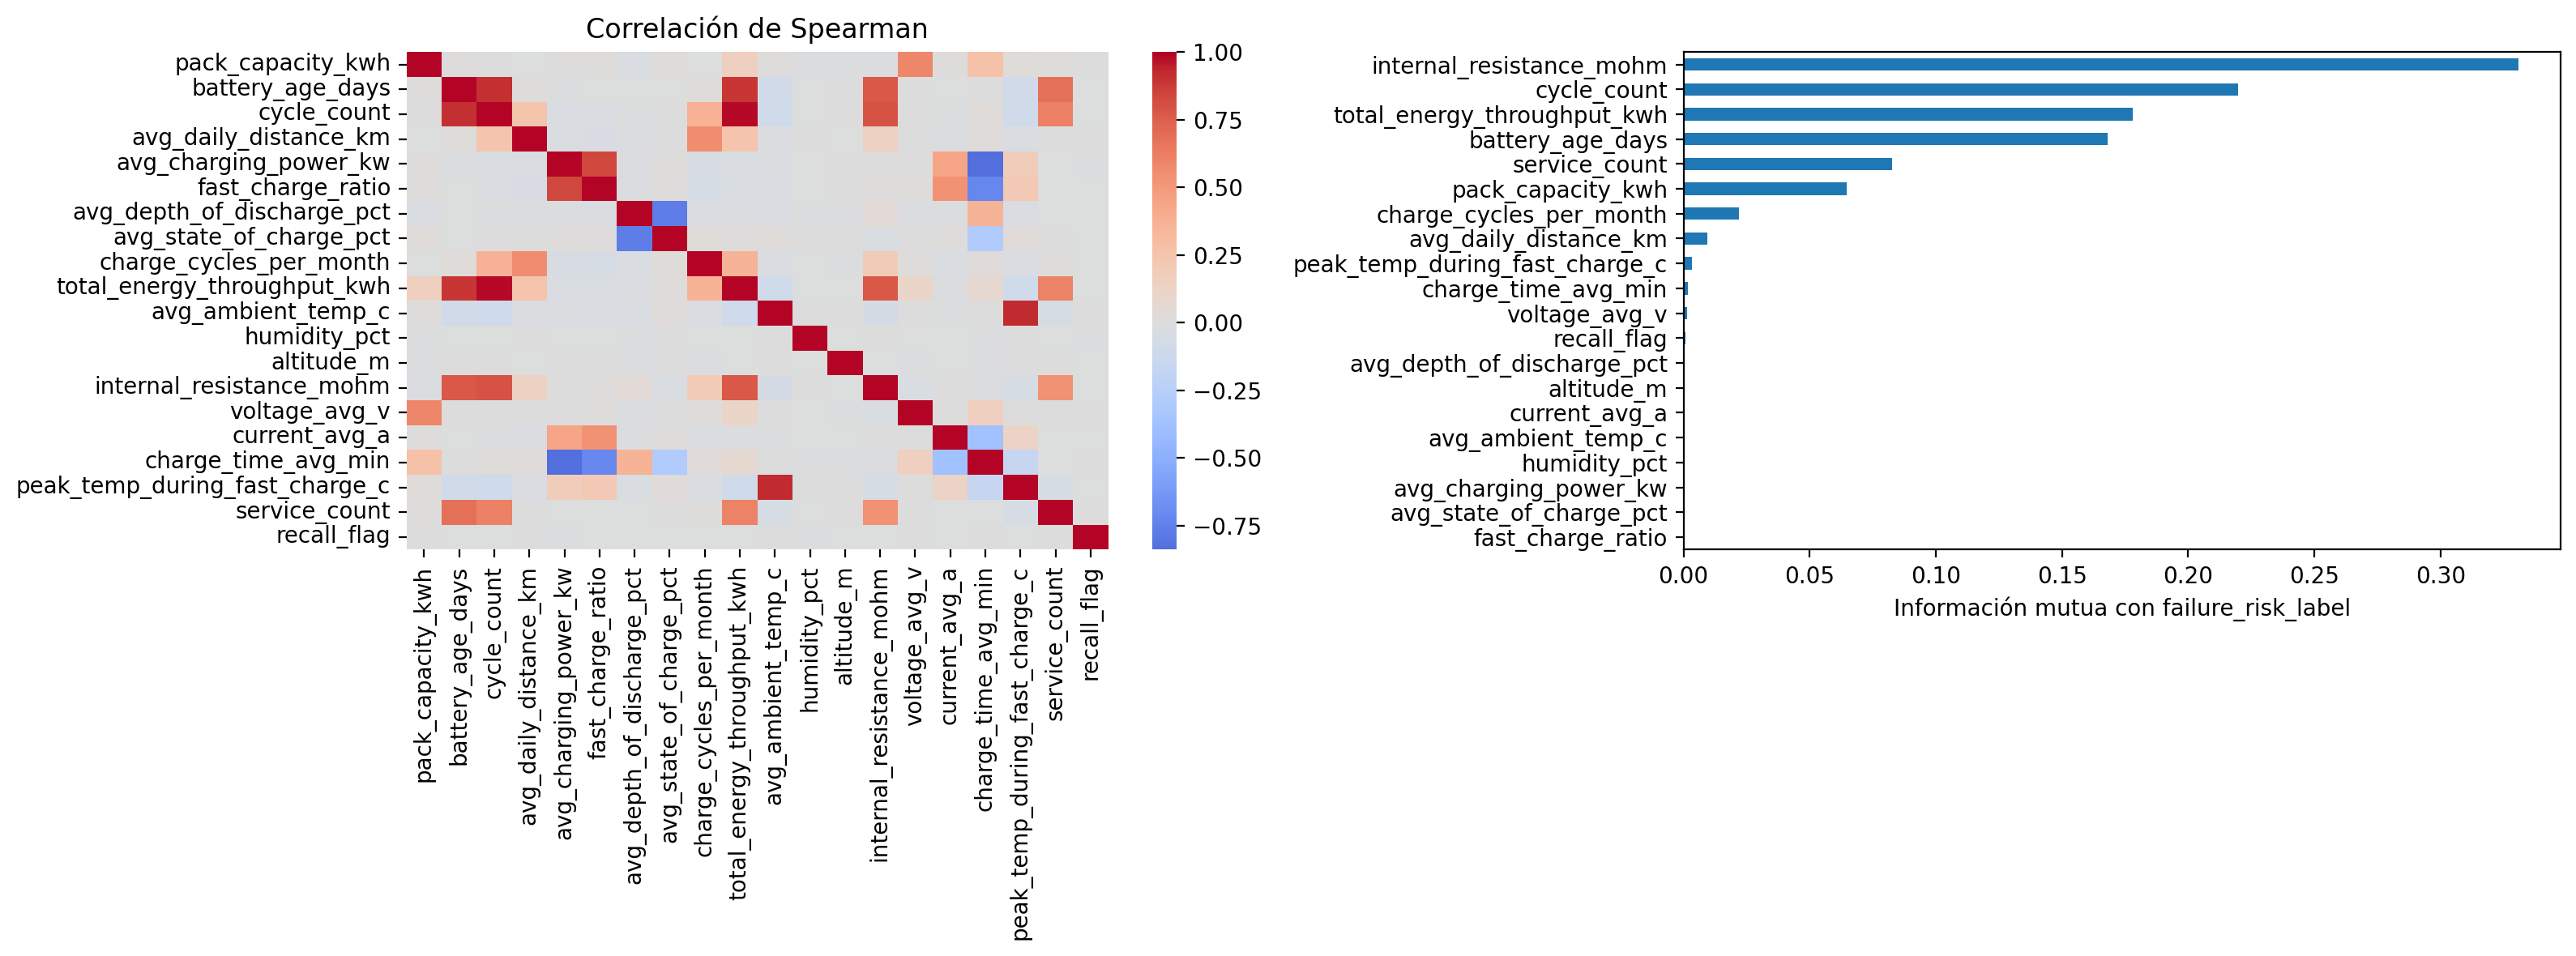

Duplicados: 0


In [ ]:
# 1. ¿Los atributos de un paquete son constantes? Si el máximo es 1, un faltante
#    se puede recuperar con otra lectura de la misma batería.
est = ["chemistry","manufacturer","vehicle_model","pack_capacity_kwh","manufacture_date","climate_zone"]
display(df.groupby("battery_id")[est].nunique().max())

# 2. Figuras para el informe: Spearman de predictores numéricos e información mutua
excl = ["state_of_health_pct","remaining_useful_life_cycles","capacity_fade_pct"]
fn = [c for c in num.columns if c not in excl]
plt.rcParams["figure.dpi"] = 200
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[fn].corr(method="spearman"), cmap="coolwarm", center=0, ax=ax[0])
ax[0].set_title("Correlación de Spearman")
mi[fn].sort_values().plot.barh(ax=ax[1])
ax[1].set_xlabel("Información mutua con failure_risk_label")
plt.tight_layout(); plt.show()
print("Duplicados:", df.duplicated().sum())

1. Gráfico para la Correlación de Spearman entre predictores numéricos

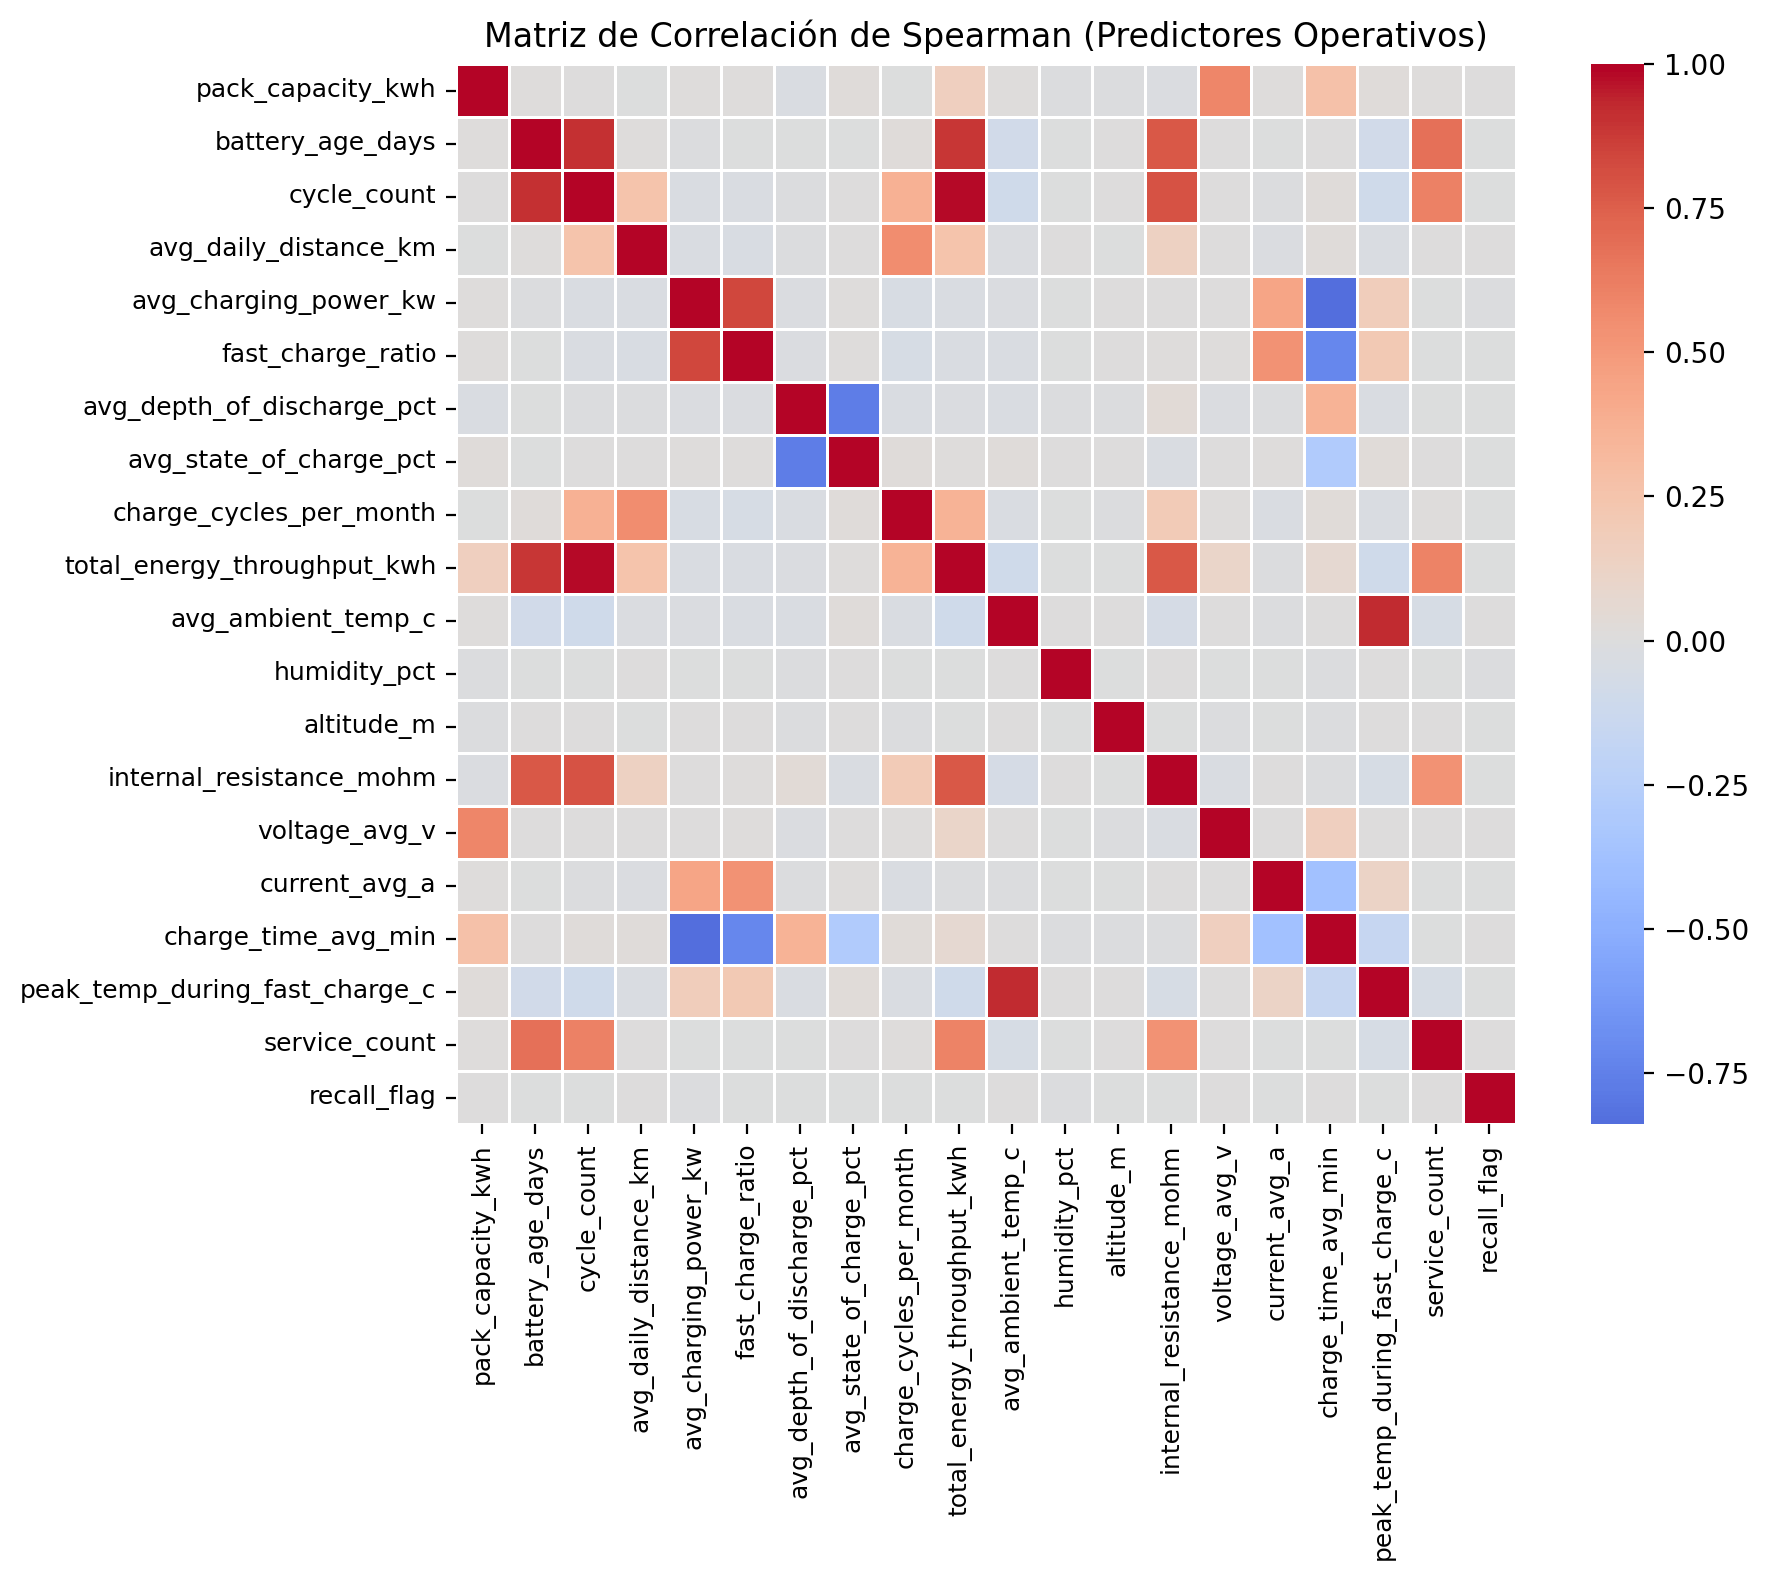

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Excluir las variables para evitar fuga de información
excl = ["state_of_health_pct", "remaining_useful_life_cycles", "capacity_fade_pct"]
fn = [c for c in num.columns if c not in excl]

# 2. Configurar la figura solo para el mapa de calor de Spearman
plt.figure(figsize=(10, 8))
plt.rcParams["figure.dpi"] = 200

sns.heatmap(
    df[fn].corr(method="spearman"), 
    cmap="coolwarm", 
    center=0, 
    annot=False, 
    square=True, 
    linewidths=0.5
)

plt.title("Matriz de Correlación de Spearman (Predictores Operativos)")
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

2. Gráfico para la Información Mutua con failure_risk_label

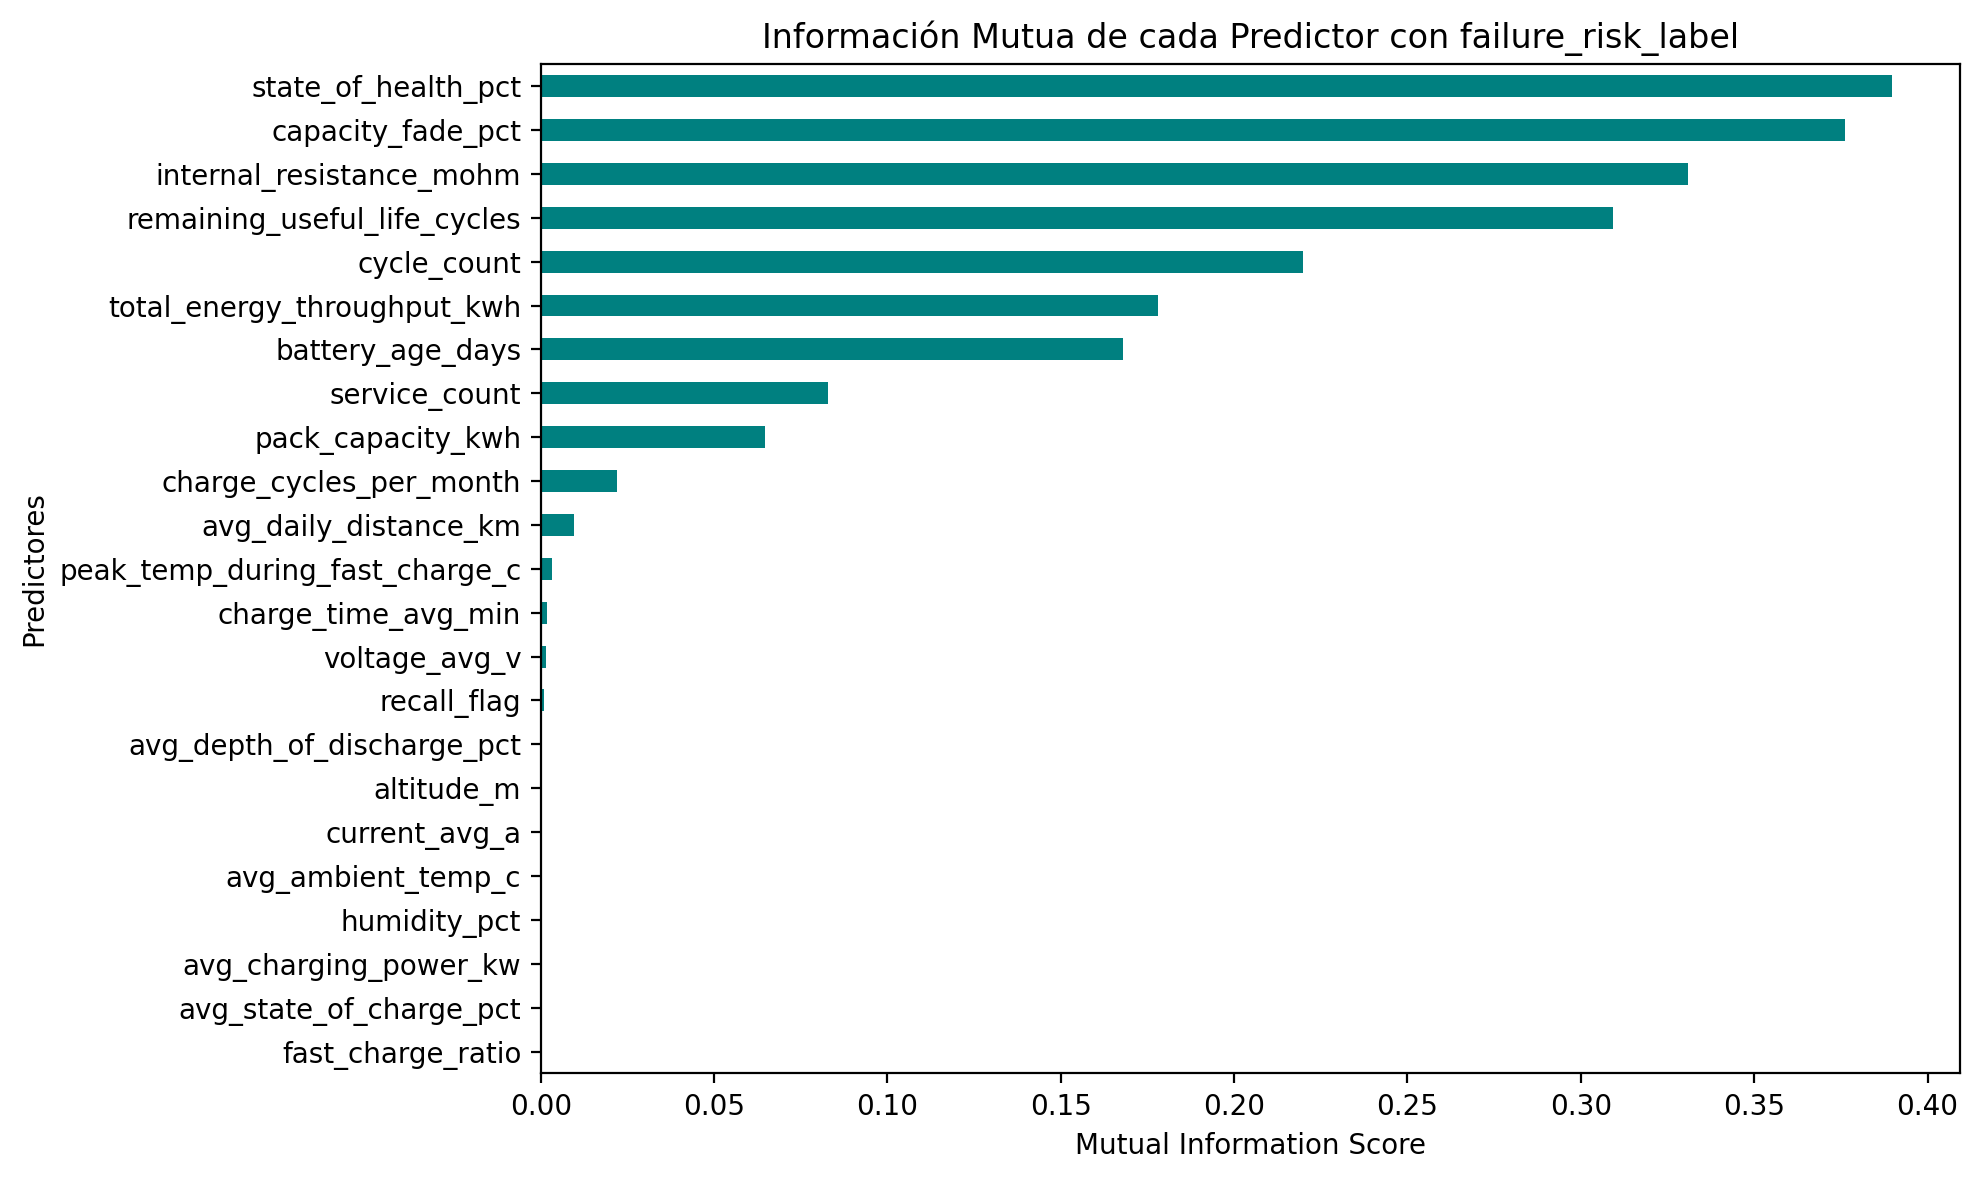

In [11]:
plt.figure(figsize=(10, 6))
# Ordenamos los valores de mayor a menor para mejor lectura
mi_sorted = mi.sort_values(ascending=True)

mi_sorted.plot(kind="barh", color="teal")
plt.title("Información Mutua de cada Predictor con failure_risk_label")
plt.xlabel("Mutual Information Score")
plt.ylabel("Predictores")
plt.tight_layout()
plt.show()